<a href="https://colab.research.google.com/github/adityaraj9053/Defending-Against-Adversarial-Attack/blob/main/GAN_Adversarial_Defense_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Defending Against Adversarial Attacks Through GANs (IEEE SPL 2025)
### Colab-ready educational reproduction

**Workflow:** Download MNIST/CIFAR-10 → train target classifier → freeze target → train GAN perturbation generator → evaluate five adversarial attacks → visualize results.

**Important:** This is an approximate reimplementation, **not official authors’ code**. The paper specifies three objectives, batch size 128, Adam, StepLR, discriminator-to-generator ratio 3:1, a residual encoder/decoder generator, and spectral-normalized discriminator, but not all exact architectural/training details. The code makes explicit engineering choices. Results will differ from paper Tables II–VI.

**Security note:** Both fixed-classifier attacks and stronger *adaptive* attacks against the entire defended pipeline are evaluated. Accuracy on fixed-classifier attacks alone does **not** establish robustness to adaptive adversaries.

Select **Runtime → Change runtime type → GPU**.

In [ ]:
!pip install -q requests==2.32.4 urllib3>=2.0.0 idna>=3.18

In [ ]:
!pip install -q torchattacks pandas matplotlib tqdm

## 1. Configuration and dataset code

Set `DATASET="MNIST"` for a fast first experiment, or `"CIFAR10"` for the harder ResNet experiment. Datasets download automatically through `torchvision.datasets` to `/content/data`. To train on the entire dataset, change `TRAIN_SAMPLES=None` and `TEST_SAMPLES=None` and increase epochs.

In [ ]:
import os, random, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
import torchattacks
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

DATASET = "MNIST"     # "MNIST" or "CIFAR10"
TRAIN_SAMPLES = 12000 # None = all training images
TEST_SAMPLES = 500    # None = all test images; CW & OnePixel can be slow
BATCH_SIZE = 128      # paper setting
CLASSIFIER_EPOCHS = 4 if DATASET == "MNIST" else 8
GAN_EPOCHS = 5 if DATASET == "MNIST" else 8
LR_CLASSIFIER = 1e-3
LR_GAN = 2e-4
C_NORM = 0.2          # paper hinge threshold
DELTA_SCALE = 0.3 if DATASET == "MNIST" else 0.05 # chosen engineering hyperparameter
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print('Device:', DEVICE, '| Dataset:', DATASET)

def load_dataset(name, train_samples=None, test_samples=None):
    tfm = transforms.ToTensor()  # output range [0,1], no Normalize
    cls = datasets.MNIST if name == "MNIST" else datasets.CIFAR10
    train_set = cls(root='/content/data', train=True, download=True, transform=tfm)
    test_set = cls(root='/content/data', train=False, download=True, transform=tfm)
    if train_samples is not None:
        idx = np.random.default_rng(SEED).permutation(len(train_set))[:train_samples]
        train_set = Subset(train_set, idx.tolist())
    if test_samples is not None:
        idx = np.random.default_rng(SEED + 1).permutation(len(test_set))[:test_samples]
        test_set = Subset(test_set, idx.tolist())
    tr_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                           num_workers=2, pin_memory=torch.cuda.is_available())
    te_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False,
                           num_workers=2, pin_memory=torch.cuda.is_available())
    channels = 1 if name == 'MNIST' else 3
    return tr_loader, te_loader, channels

train_loader, test_loader, CHANNELS = load_dataset(DATASET, TRAIN_SAMPLES, TEST_SAMPLES)
print('Training examples:', len(train_loader.dataset), '| Test examples:', len(test_loader.dataset))

Device: cpu | Dataset: MNIST


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.86MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 155kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.46MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.5MB/s]

Training examples: 12000 | Test examples: 500


## 2. Target network — MNIST CNN / CIFAR-10 ResNet34
Paper trains MNIST models A/B/C and ResNet18/34 for CIFAR-10. This notebook uses one representative MNIST CNN or ResNet34 (not an exact reproduction of architecture C). **Target weights are frozen during GAN training.**

In [ ]:
class MNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64*7*7, 128),
                                        nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 10))
    def forward(self, x): return self.classifier(self.features(x))

def make_target():
    if DATASET == 'MNIST': return MNISTCNN().to(DEVICE)
    net = models.resnet34(weights=None, num_classes=10)
    net.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    net.maxpool = nn.Identity()
    return net.to(DEVICE)

target = make_target()

def accuracy(model, loader):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for x,y in loader:
            x,y=x.to(DEVICE), y.to(DEVICE)
            correct += (model(x).argmax(1)==y).sum().item()
            total += y.numel()
    return 100*correct/total

def train_target(model):
    opt = torch.optim.Adam(model.parameters(), lr=LR_CLASSIFIER)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, CLASSIFIER_EPOCHS//2), gamma=0.5)
    for ep in range(CLASSIFIER_EPOCHS):
        model.train(); total_loss=0
        for x,y in tqdm(train_loader, desc=f'Target epoch {ep+1}/{CLASSIFIER_EPOCHS}', leave=False):
            x,y=x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss=F.cross_entropy(model(x),y)
            loss.backward(); opt.step()
            total_loss += loss.item()*len(y)
        sched.step()
        print(f'Target epoch {ep+1}: loss={total_loss/len(train_loader.dataset):.4f}, '
              f'test accuracy={accuracy(model,test_loader):.2f}%')
    return model

target = train_target(target)
torch.save(target.state_dict(), f'/content/{DATASET.lower()}_target.pt')
for p in target.parameters(): p.requires_grad_(False)
target.eval()
print('Clean target accuracy:', accuracy(target,test_loader))

Target epoch 1/4:   0%|          | 0/94 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f84ac1a2fc0><function _MultiProcessingDataLoaderIter.__del__ at 0x7f84ac1a2fc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    
self._shutdown_workers()
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        if w.is_alive():self._shutdown_workers()

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    assert self._parent_pid == os.getpid(), 'can only test a child process'    
if w.is_alive():AssertionError
:   File "/usr/lib/python3.13/multiprocessing/pro

Target epoch 1: loss=0.8492, test accuracy=91.20%


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f84ac1a2fc0>

Target epoch 2/4:   0%|          | 0/94 [00:00<?, ?it/s]

...

Target epoch 4/4:   0%|          | 0/94 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f84ac1a2fc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f84ac1a2fc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Target epoch 4: loss=0.1269, test accuracy=97.00%


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f84ac1a2fc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f84ac1a2fc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Clean target accuracy: 97.0


## 3. Generator and discriminator
Generator outputs **additive perturbation**, not a generated image. Defense is `clamp(x+G(x),0,1)`. Discriminator distinguishes real `x` from protected `x+G(x)`.

In [ ]:
class ResidualBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.net=nn.Sequential(nn.Conv2d(ch,ch,3,padding=1), nn.InstanceNorm2d(ch,affine=True),nn.ReLU(),
                               nn.Conv2d(ch,ch,3,padding=1),nn.InstanceNorm2d(ch,affine=True))
    def forward(self,x): return F.relu(x+self.net(x))

class Generator(nn.Module):
    def __init__(self, in_ch, scale):
        super().__init__(); self.scale=scale
        self.net=nn.Sequential(
            nn.Conv2d(in_ch,32,3,padding=1),nn.ReLU(),
            nn.Conv2d(32,64,3,stride=2,padding=1),nn.InstanceNorm2d(64,affine=True),nn.ReLU(),
            ResidualBlock(64),ResidualBlock(64),
            nn.Upsample(scale_factor=2,mode='nearest'),
            nn.Conv2d(64,32,3,padding=1),nn.ReLU(),
            nn.Conv2d(32,in_ch,3,padding=1),nn.Tanh())
    def forward(self,x): return self.scale*self.net(x)

from torch.nn.utils import spectral_norm
class Discriminator(nn.Module):
    def __init__(self, in_ch):
        super().__init__()
        layers=[]; prev=in_ch
        for ch in (32,64,128):
            layers += [spectral_norm(nn.Conv2d(prev,ch,3,stride=2,padding=1)),
                       nn.LeakyReLU(0.2,inplace=True)]
            prev=ch
        self.features=nn.Sequential(*layers)
        self.head=spectral_norm(nn.Conv2d(128,1,3,padding=1))
    def forward(self,x):
        return self.head(self.features(x)).mean(dim=(1,2,3)) # logits

G=Generator(CHANNELS,DELTA_SCALE).to(DEVICE)
D=Discriminator(CHANNELS).to(DEVICE)

def protect(x): return torch.clamp(x + G(x),0,1)

print('Generator params:',sum(p.numel() for p in G.parameters()))
print('Discriminator params:',sum(p.numel() for p in D.parameters()))

Generator params: 185921
Discriminator params: 93825


## 4. Train the GAN defense
Three paper-inspired objectives:
- `Loss1 = CE(target(x+G(x)),y)` preserves labels.
- `Loss2` uses **standard discriminator logistic adversarial loss** applied to protected images (the paper writes generic GAN minimax notation).
- `Loss3 = mean(max(0, ||G(x)||₂ - 0.2))` limits perturbation.

For numerical stability, logistic GAN losses use `BCEWithLogitsLoss`; relative weights are set to 1, like the published conceptual combination. The norm is computed **per image**. The discriminator updates three times per generator update (3:1), using new minibatches.

In [ ]:
opt_g=torch.optim.Adam(G.parameters(),lr=LR_GAN,betas=(0.5,0.999))
opt_d=torch.optim.Adam(D.parameters(),lr=LR_GAN,betas=(0.5,0.999))
sched_g=torch.optim.lr_scheduler.StepLR(opt_g,step_size=max(1,GAN_EPOCHS//2),gamma=0.5)
sched_d=torch.optim.lr_scheduler.StepLR(opt_d,step_size=max(1,GAN_EPOCHS//2),gamma=0.5)
bce=nn.BCEWithLogitsLoss()

def d_step(x):
    D.train(); G.train()
    with torch.no_grad(): fake=protect(x)
    real_logit=D(x); fake_logit=D(fake)
    loss_d=bce(real_logit,torch.ones_like(real_logit))+bce(fake_logit,torch.zeros_like(fake_logit))
    opt_d.zero_grad(set_to_none=True);loss_d.backward();opt_d.step()
    return loss_d.item()

def g_step(x,y):
    G.train()
    # Temporarily freeze D weights while allowing gradients to propagate THROUGH D to G
    for p in D.parameters(): p.requires_grad_(False)
    generated=G(x)
    fake=torch.clamp(x+generated,0,1)
    loss1=F.cross_entropy(target(fake),y)
    fake_logits=D(fake)
    loss2=bce(fake_logits,torch.ones_like(fake_logits))
    norm=torch.flatten(generated,start_dim=1).norm(p=2,dim=1)
    loss3=F.relu(norm-C_NORM).mean()
    total=loss1+loss2+loss3
    opt_g.zero_grad(set_to_none=True);total.backward();opt_g.step()
    for p in D.parameters():p.requires_grad_(True)
    return loss1.item(),loss2.item(),loss3.item()

history=[]
for epoch in range(GAN_EPOCHS):
    sum_d=0; sums=np.zeros(3); updates=0
    iterator=iter(train_loader)
    progress=tqdm(total=len(train_loader),desc=f'GAN epoch {epoch+1}/{GAN_EPOCHS}',leave=False)
    while True:
        for k in range(3):
            try: x,y=next(iterator)
            except StopIteration: break
            x=x.to(DEVICE); y=y.to(DEVICE)
            sum_d+=d_step(x); progress.update(1)
        else:
            # 3 D updates completed; use the latest minibatch for the G update
            sums+=np.array(g_step(x,y));updates+=1
            continue
        break
    progress.close(); sched_g.step();sched_d.step()
    print(f'GAN epoch {epoch+1}: D={sum_d/max(1,len(train_loader)):.3f}, '
          f'L1/L2/L3={(sums/max(1,updates)).round(4)}')
    history.append({'epoch':epoch+1,'loss1':sums[0]/max(1,updates),
                    'loss2':sums[1]/max(1,updates),'loss3':sums[2]/max(1,updates)})

G.eval();D.eval()
torch.save(G.state_dict(),f'/content/{DATASET.lower()}_generator.pt')
print('Generator saved.')

GAN epoch 1/5:   0%|          | 0/94 [00:00<?, ?it/s]

GAN epoch 1: D=1.383, L1/L2/L3=[0.0779 0.6934 0.3588]


GAN epoch 2/5:   0%|          | 0/94 [00:00<?, ?it/s]

GAN epoch 2: D=1.385, L1/L2/L3=[8.410e-02 6.955e-01 5.000e-04]


GAN epoch 3/5:   0%|          | 0/94 [00:00<?, ?it/s]

GAN epoch 3: D=1.385, L1/L2/L3=[7.810e-02 6.943e-01 2.000e-04]


GAN epoch 4/5:   0%|          | 0/94 [00:00<?, ?it/s]

GAN epoch 4: D=1.386, L1/L2/L3=[7.590e-02 6.933e-01 1.000e-04]


GAN epoch 5/5:   0%|          | 0/94 [00:00<?, ?it/s]

GAN epoch 5: D=1.386, L1/L2/L3=[9.280e-02 6.935e-01 1.000e-04]
Generator saved.


## 5. Define a defended classifier and evaluate clean images

Clean accuracy, no defense: 97.0
Clean accuracy, with GAN defense: 97.0


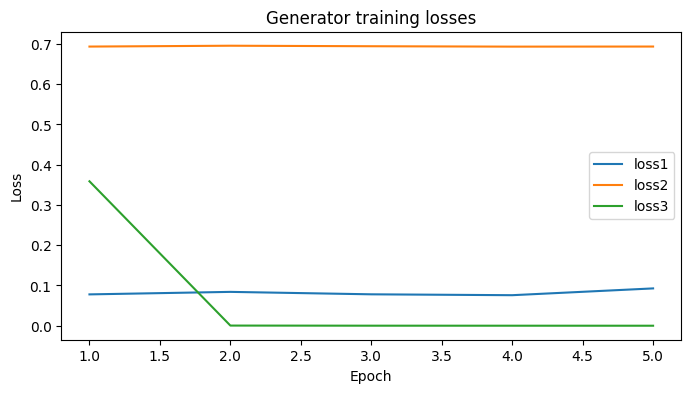

In [ ]:
class DefendedClassifier(nn.Module):
    def __init__(self,generator,classifier):
        super().__init__(); self.generator=generator; self.classifier=classifier
    def forward(self,x): return self.classifier(torch.clamp(x+self.generator(x),0,1))

defended=DefendedClassifier(G,target).to(DEVICE).eval()
print('Clean accuracy, no defense:',accuracy(target,test_loader))
print('Clean accuracy, with GAN defense:',accuracy(defended,test_loader))

pd.DataFrame(history).set_index('epoch').plot(title='Generator training losses',figsize=(8,4))
plt.xlabel('Epoch');plt.ylabel('Loss');plt.show()

## 6. Five attacks and output table
We use `torchattacks` implementations for FGSM, PGD, OnePixel, DeepFool, CW.

Two evaluations:
- **Fixed-target:** Attack the original classifier, then pass the same perturbed images through the defense. This corresponds to a non-adaptive / transfer-style evaluation and is broadly analogous to the paper's fixed-target assessment.
- **Adaptive:** Attack the **entire** defended pipeline (gradient through G). This is essential for an honest robustness check.

**Runtime:** OnePixel and CW can take a long time, especially on CPU. Use `ATTACK_TEST_SAMPLES=100` at first; increase for a more reliable estimate. Attack hyperparameters are examples, not claimed exact reproduction for every dataset.

In [ ]:
ATTACK_TEST_SAMPLES = 100  # change to 500 or more for stronger estimates
ATTACKS_TO_RUN = ['FGSM','PGD','DeepFool','CW','OnePixel']
RUN_ADAPTIVE = True

def create_attacks(model):
    eps = 0.3 if DATASET=='MNIST' else 8/255
    return {
        'FGSM': torchattacks.FGSM(model,eps=eps),
        'PGD': torchattacks.PGD(model,eps=eps,alpha=2/255,steps=10,random_start=True),
        'DeepFool': torchattacks.DeepFool(model,steps=50,overshoot=0.02),
        'CW': torchattacks.CW(model,c=1,lr=0.01,steps=50,kappa=0),
        'OnePixel': torchattacks.OnePixel(model,pixels=1,steps=10,popsize=10),
    }

# Reuse the same test examples for every method
xs=[]; ys=[]; gathered=0
for x,y in test_loader:
    k=min(len(x),ATTACK_TEST_SAMPLES-gathered)
    xs.append(x[:k]);ys.append(y[:k]);gathered+=k
    if gathered>=ATTACK_TEST_SAMPLES:break
X=torch.cat(xs).to(DEVICE);Y=torch.cat(ys).to(DEVICE)

def batched_predict_correct(model, images, labels, batch=64):
    count=0
    model.eval()
    with torch.no_grad():
        for st in range(0,len(images),batch):
            count+=(model(images[st:st+batch]).argmax(1)==labels[st:st+batch]).sum().item()
    return 100*count/len(labels)

def make_adversarial(attack,images,labels,batch=16):
    results=[]
    for st in tqdm(range(0,len(images),batch),desc=type(attack).__name__,leave=False):
        a=attack(images[st:st+batch],labels[st:st+batch]).detach()
        results.append(a)
    return torch.cat(results)

base_attacks=create_attacks(target)
adaptive_attacks=create_attacks(defended) if RUN_ADAPTIVE else {}
results=[]; samples={}
for name in ATTACKS_TO_RUN:
    print('Evaluating',name)
    adv=make_adversarial(base_attacks[name],X,Y)
    base_acc=batched_predict_correct(target,adv,Y)
    defend_acc=batched_predict_correct(defended,adv,Y)
    row={'Attack':name,'Unprotected accuracy (%)':round(base_acc,2),
         'GAN accuracy vs fixed attack (%)':round(defend_acc,2),
         'Unprotected error (%)':round(100-base_acc,2),
         'GAN error vs fixed attack (%)':round(100-defend_acc,2)}
    samples[name]=adv[:8].detach().cpu()
    if RUN_ADAPTIVE:
        adv_adaptive=make_adversarial(adaptive_attacks[name],X,Y)
        adaptive_acc=batched_predict_correct(defended,adv_adaptive,Y)
        row['GAN accuracy vs adaptive attack (%)']=round(adaptive_acc,2)
        row['GAN error vs adaptive attack (%)']=round(100-adaptive_acc,2)
    results.append(row)
    print(row)
report=pd.DataFrame(results)
display(report)
report.to_csv('/content/gan_attack_results.csv',index=False)
print('Results saved to /content/gan_attack_results.csv')

Evaluating FGSM


FGSM:   0%|          | 0/7 [00:00<?, ?it/s]

FGSM:   0%|          | 0/7 [00:00<?, ?it/s]

{'Attack': 'FGSM', 'Unprotected accuracy (%)': 4.0, 'GAN accuracy vs fixed attack (%)': 4.0, 'Unprotected error (%)': 96.0, 'GAN error vs fixed attack (%)': 96.0, 'GAN accuracy vs adaptive attack (%)': 26.0, 'GAN error vs adaptive attack (%)': 74.0}
Evaluating PGD


PGD:   0%|          | 0/7 [00:00<?, ?it/s]

...

OnePixel:   0%|          | 0/7 [00:00<?, ?it/s]

OnePixel:   0%|          | 0/7 [00:00<?, ?it/s]

{'Attack': 'OnePixel', 'Unprotected accuracy (%)': 95.0, 'GAN accuracy vs fixed attack (%)': 95.0, 'Unprotected error (%)': 5.0, 'GAN error vs fixed attack (%)': 5.0, 'GAN accuracy vs adaptive attack (%)': 95.0, 'GAN error vs adaptive attack (%)': 5.0}


,Attack,Unprotected accuracy (%),GAN accuracy vs fixed attack (%),Unprotected error (%),GAN error vs fixed attack (%),GAN accuracy vs adaptive attack (%),GAN error vs adaptive attack (%)
0,FGSM,4.0,4.0,96.0,96.0,26.0,74.0
1,PGD,60.0,61.0,40.0,39.0,65.0,35.0
2,DeepFool,45.0,89.0,55.0,11.0,42.0,58.0
3,CW,93.0,94.0,7.0,6.0,93.0,7.0
4,OnePixel,95.0,95.0,5.0,5.0,95.0,5.0


Results saved to /content/gan_attack_results.csv


## 7. Image output — original / attacked / defended
**Note:** Protected images below use the *fixed-target adversarial* examples; the prediction shown is from the corresponding network. These are actual images generated in your run, not sample illustrations.

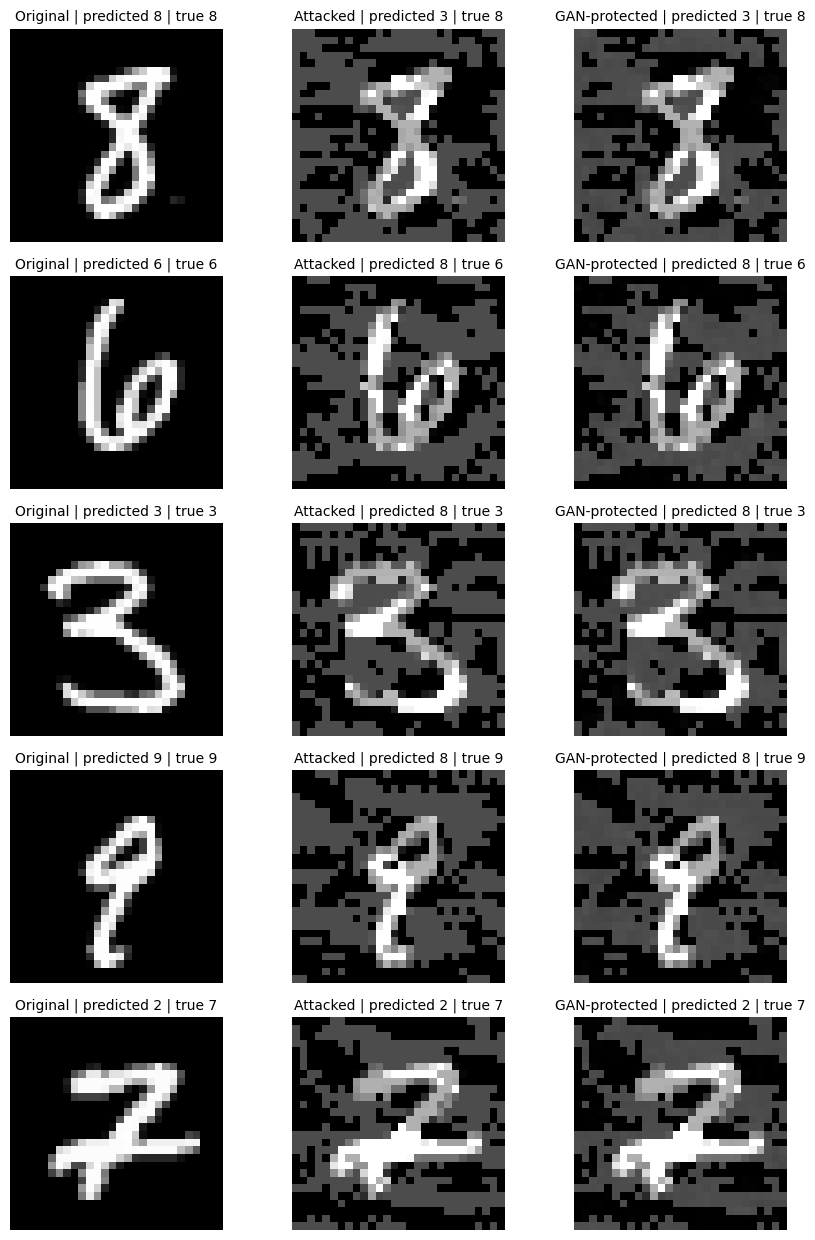

In [ ]:
ATTACK_TO_VISUALIZE='FGSM'  # try 'PGD' or 'CW'
adv=samples[ATTACK_TO_VISUALIZE].to(DEVICE)
original=X[:len(adv)]
with torch.no_grad():
    protected=protect(adv)
    pred_orig=target(original).argmax(1)
    pred_attack=target(adv).argmax(1)
    pred_def=target(protected).argmax(1)

def image_np(t):
    arr=t.detach().cpu().permute(1,2,0).numpy().clip(0,1)
    return arr[:,:,0] if arr.shape[2]==1 else arr

N=min(5,len(adv));fig,axes=plt.subplots(N,3,figsize=(9,2.5*N),squeeze=False)
for i in range(N):
    for j,(im,title,pred) in enumerate([
        (original[i],'Original',pred_orig[i]),
        (adv[i],'Attacked',pred_attack[i]),
        (protected[i],'GAN-protected',pred_def[i])]):
        axes[i,j].imshow(image_np(im),cmap='gray' if CHANNELS==1 else None)
        axes[i,j].set_title(f'{title} | predicted {int(pred)} | true {int(Y[i])}',fontsize=10)
        axes[i,j].axis('off')
plt.tight_layout();plt.show()

## 8. Save and download trained models / data outputs

In [ ]:
from google.colab import files
# Run desired download lines (uncomment):
# files.download(f'/content/{DATASET.lower()}_target.pt')
# files.download(f'/content/{DATASET.lower()}_generator.pt')
# files.download('/content/gan_attack_results.csv')
print('Target and generator checkpoints, and results CSV, are saved under /content/.')

Target and generator checkpoints, and results CSV, are saved under /content/.


## Interpreting your output and differences from the paper
- **Accuracy (%)** = correctly classified examples / examples tested × 100. **Error (%)** = 100 − accuracy.
- The paper's highlighted results: MNIST model C FGSM **91.49% → 0.87% error**; PGD **48.58% → 1.28%**. CIFAR-10 ResNet34 FGSM **52.2% → 48.4%**; PGD **96.06% → 94.97%**. Those are *reported paper numbers*, not guaranteed notebook outputs.
- This sample implementation uses a CNN that is not the paper's exact model C, limited epochs/subsets, a selected generator, and chosen perturbation scaling. Therefore **expect different numbers**.
- A small evaluation set has high uncertainty, and weak attack implementations or non-adaptive evaluation can misleadingly inflate robustness. For credible research, use the full test set and adaptive attacks; consider EOT/BPDA if needed and verify attack success against the defended pipeline.
- OnePixel and CW are computationally expensive. Increasing test samples and epochs is advisable once the pipeline is validated.
- The term "defended image" here means the classifier input after the generator's additive transformation; it need not undo the visual attack.
